# Which Penguin? — Species Classification with a Production-Style Pipeline

Predict whether a penguin is an **Adelie**, **Chinstrap** or **Gentoo** from its bill, flipper and body measurements, island and sex, using the [Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/) dataset.

The goal is not just accuracy but a **single deployable artifact**: a scikit-learn `Pipeline` that takes *raw* rows (including missing values and unseen categories) and returns a prediction.

**Outline**
1. Load & explore the data
2. Train/test split
3. Build the preprocessing + model pipeline
4. Tune regularisation with cross-validation
5. Evaluate on the held-out test set
6. Interpret the model
7. Save the model

In [ ]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
from sklearn import set_config
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

from which_penguin.pipeline import (
    NUMERIC_FEATURES, PARAM_GRID,
    build_pipeline, load_data, split_data, tune,
)

set_config(transform_output="pandas", display="diagram")
sns.set_theme(style="ticks", font_scale=0.8, rc={"figure.figsize": (6, 4)})

FIGURES = Path("../reports/figures")
MODELS = Path("../models")
FIGURES.mkdir(parents=True, exist_ok=True)

## 1. Load & explore the data

In [23]:
data = load_data()
print(f"Data shape: {data.shape}")
data.head()

Data shape: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


Missing values per column. A few rows lack measurements and several lack `sex` — the pipeline will impute these rather than dropping rows, so the deployed model can also cope with incomplete input.

In [24]:
data.isna().sum()

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [25]:
data["species"].value_counts()

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Classes are imbalanced (Chinstrap is the smallest), so the train/test split is **stratified** by species.

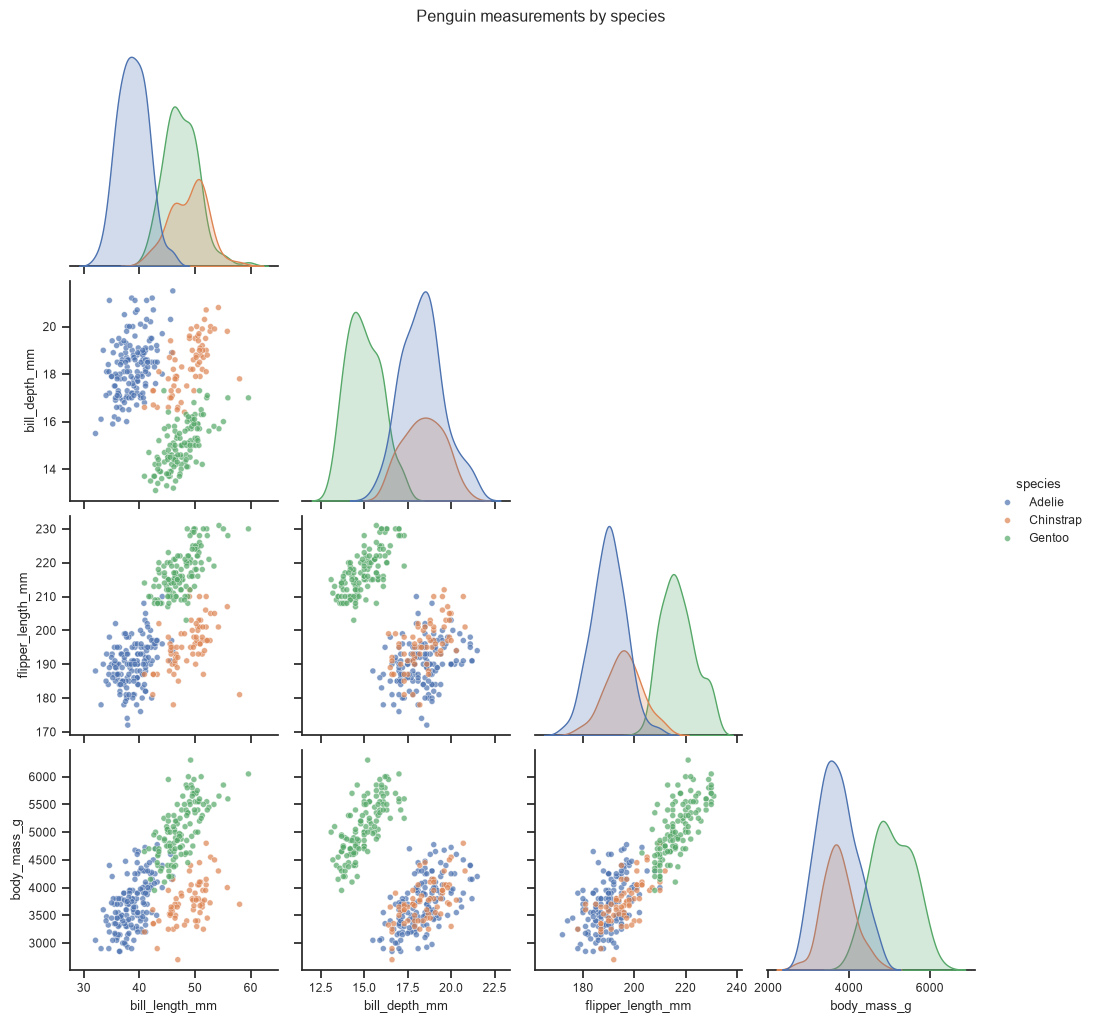

In [26]:
g = sns.pairplot(data, hue="species", vars=NUMERIC_FEATURES, corner=True,
                 plot_kws={"alpha": 0.7, "s": 18})
g.figure.suptitle("Penguin measurements by species", y=1.02)
g.savefig(FIGURES / "pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

Gentoo separates cleanly on flipper length and body mass; Adelie vs. Chinstrap is mainly distinguished by **bill length**. A linear model should do well here.

## 2. Train/test split

The test set is held out until the very end — all model selection happens via cross-validation on the training set.

In [27]:
X_train, X_test, y_train, y_test = split_data(data)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (275, 6), Test: (69, 6)


## 3. Build the pipeline

`build_pipeline()` (in `src/which_penguin/pipeline.py`) chains:

| Step | Numeric features | Categorical features |
|---|---|---|
| Impute | median | most frequent |
| Transform | `StandardScaler` | `OneHotEncoder(handle_unknown="ignore")` |
| Model | `LogisticRegression(solver="saga")` | |

Because imputation and scaling are fitted *inside* the pipeline, cross-validation never leaks test-fold statistics into training.

In [28]:
pipeline = build_pipeline()

## 4. Tune with cross-validation

Grid search over regularisation strength `C` and type (`l1_ratio=0` → L2, `l1_ratio=1` → L1), scored by 5-fold CV accuracy.

In [29]:
PARAM_GRID

{'classifier__C': [0.01, 0.1, 1.0, 10.0, 100.0],
 'classifier__l1_ratio': [0.0, 1.0]}

In [30]:
search = tune(X_train, y_train)
model = search.best_estimator_

print(f"Best params:    {search.best_params_}")
print(f"CV Train accuracy:    {search.best_score_:.4f}")


Best params:    {'classifier__C': 10.0, 'classifier__l1_ratio': 0.0}
CV Train accuracy:    0.9964


In [31]:
cv_results = (
    pd.DataFrame(search.cv_results_)
    .pivot(index="param_classifier__C", columns="param_classifier__l1_ratio",
           values="mean_test_score")
    .rename(columns={0.0: "L2", 1.0: "L1"})
)
cv_results.round(4)

param_classifier__l1_ratio,L2,L1
param_classifier__C,,
0.01,0.9236,0.4436
0.10,0.9818,0.9745
1.00,0.9927,0.9927
10.00,0.9964,0.9964
100.00,0.9964,0.9927


Very strong regularisation (`C=0.01`) underfits; beyond `C≈1` accuracy plateaus near 99%.

## 5. Evaluate on the held-out test set

In [32]:
y_pred = model.predict(X_test)
print(f"Test accuracy: {model.score(X_test, y_test):.4f}\n")
print(classification_report(y_test, y_pred))

Test accuracy: 0.9855

              precision    recall  f1-score   support

      Adelie       1.00      0.97      0.98        30
   Chinstrap       0.93      1.00      0.97        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           0.99        69
   macro avg       0.98      0.99      0.98        69
weighted avg       0.99      0.99      0.99        69



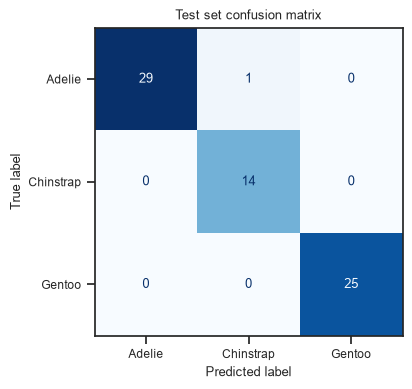

In [33]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Test set confusion matrix")
fig.savefig(FIGURES / "confusion_matrix.png", dpi=120, bbox_inches="tight")
plt.show()

With only 69 test penguins, a single misclassification moves accuracy by ~1.4 points, so the CV score is the more reliable estimate of generalisation.

## 6. Interpret the model

Coefficients are on standardised features, so their magnitudes are comparable. Positive values push towards that species.

In [47]:
clf = model.named_steps["classifier"]
preprocessor = model.named_steps["preprocessor"]

print(f"Classifier: {clf}")
print(f"Preprocessor: {preprocessor}")

feature_names = preprocessor.get_feature_names_out()
coef_df = pd.DataFrame(clf.coef_.T, index=feature_names, columns=clf.classes_)
coef_df

Classifier: LogisticRegression(C=10.0, max_iter=5000, random_state=42, solver='saga')
Preprocessor: ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['bill_length_mm', 'bill_depth_mm',
                                  'flipper_length_mm', 'body_mass_g']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['island', 'sex'])],
       

,Adelie,Chinstrap,Gentoo
bill_length_mm,-4.411328,3.375643,1.035685
bill_depth_mm,1.887677,0.254113,-2.141790
flipper_length_mm,-0.502792,-0.519437,1.022229
body_mass_g,0.378731,-1.136222,0.757491
island_Biscoe,-0.428323,-1.225846,1.654170
island_Dream,-0.758432,1.806719,-1.048287
island_Torgersen,1.362113,-0.738493,-0.623620
sex_Female,-0.584716,0.921299,-0.336583
sex_Male,0.760074,-1.078920,0.318846


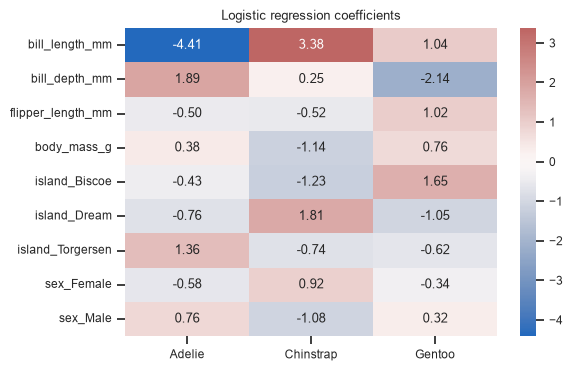

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.heatmap(coef_df, annot=True, fmt=".2f", cmap="vlag", center=0, ax=ax)
ax.set_title("Logistic regression coefficients")
fig.savefig(FIGURES / "coefficients.png", dpi=120, bbox_inches="tight")
plt.show()

Bill length is the strongest signal for Adelie (negative) vs. Chinstrap (positive); bill depth separates Gentoo (shallow bills) from the others.

## 7. Save & reload the model

The whole pipeline is a single file, so inference code only needs raw feature values.

In [ ]:
MODELS.mkdir(exist_ok=True)
model_path = MODELS / "penguin_classifier.joblib"
joblib.dump(model, model_path)

reloaded = joblib.load(model_path)
sample = X_test.iloc[[0]].copy()
sample["predicted_species"] = reloaded.predict(sample)
sample["actual_species"] = y_test.iloc[0]
sample

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,island,sex,predicted_species,actual_species
151,41.5,18.5,201.0,4000.0,Dream,Male,Adelie,Adelie


## Next steps
- Compare against tree-based models (e.g. `HistGradientBoostingClassifier`) and report CV confidence intervals.
- Serve the pipeline behind a small API (FastAPI) with input validation.
- Track experiments and model versions (e.g. MLflow).